# Аналіз затримок авіарейсів у США у 2015 році

**Курсова робота з дисципліни «Мови програмування для аналізу даних»**
Виконав: Барановський Петро Миколайович, група 401-ТН
Керівник: ст. викл. Гайтан О. М.

**Мета:** виявити закономірності затримок і скасувань внутрішніх авіарейсів США у 2015 році залежно від авіакомпанії, аеропорту, сезону та часу доби.

**Дослідницькі питання**

| № | Питання |
|---|---|
| П1 | Які авіакомпанії та аеропорти мають найвищу частку затриманих рейсів і найбільшу середню затримку? |
| П2 | Як змінюються затримки за місяцями, днями тижня та часом доби вильоту? |
| П3 | Які причини дають найбільший внесок у загальну тривалість затримок? |
| П4 | Чи пов’язана величина затримки з дальністю польоту? |
| П5 | Де і коли скасовується найбільше рейсів і з яких причин? |

**Дані:** «2015 Flight Delays and Cancellations», U.S. Department of Transportation, https://www.kaggle.com/datasets/usdot/flight-delays (ліцензія CC0).

**Структура ноутбука**
1. Налаштування середовища
2. Завантаження та первинне дослідження даних
3. Перевірка якості та попереднє опрацювання
4. Нові аналітичні ознаки
5. Об’єднання таблиць
6. Статистичний та аналітичний аналіз
7. Візуалізація
8. Експорт даних для Tableau Public
9. Висновки

## 1. Налаштування середовища

Підключаємо бібліотеки, задаємо стиль графіків і шляхи до папок проєкту. Ноутбук розрахований на запуск із папки `notebooks/`; вихідні CSV-файли мають лежати в `data/raw/` (див. README.md).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

# Шляхи до папок проєкту
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIG_DIR = PROJECT_DIR / "results" / "figures"
EXPORT_DIR = PROJECT_DIR / "results" / "exports"
for folder in (PROCESSED_DIR, FIG_DIR, EXPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Рейс вважається затриманим, якщо прибув на 15+ хв пізніше розкладу (визначення BTS)
DELAY_THRESHOLD = 15

# Назви п'яти причин затримки (поля таблиці flights)
CAUSE_COLS = {
    "AIRLINE_DELAY": "Авіакомпанія",
    "LATE_AIRCRAFT_DELAY": "Пізнє прибуття літака",
    "AIR_SYSTEM_DELAY": "Авіасистема (NAS)",
    "WEATHER_DELAY": "Погода",
    "SECURITY_DELAY": "Безпека",
}


def save_fig(fig, name):
    """Зберігає графік у results/figures для пояснювальної записки."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")


print("Папка проєкту:", PROJECT_DIR)
print("pandas", pd.__version__, "| seaborn", sns.__version__)

Папка проєкту: C:\Users\Peter\Desktop\course-project\course-project
pandas 3.1.1 | seaborn 0.13.2


## 2. Завантаження та первинне дослідження даних

Набір складається з трьох таблиць: `flights` (рейси), `airlines` (авіакомпанії), `airports` (аеропорти).

З таблиці `flights` завантажуємо 25 із 31 стовпця: технічні моменти руху літака (`WHEELS_OFF`, `WHEELS_ON`, фактичний час вильоту і прибуття тощо) для дослідницьких питань не потрібні, а вже враховані в полях затримок. Це зменшує обсяг пам’яті приблизно на чверть.

Коди аеропортів читаємо як рядки (`dtype=str`), бо частина кодів за жовтень записана цифрами, і без цього pandas змішав би типи.

In [2]:
FLIGHT_COLS = [
    "YEAR", "MONTH", "DAY", "DAY_OF_WEEK", "AIRLINE", "FLIGHT_NUMBER", "TAIL_NUMBER",
    "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "SCHEDULED_DEPARTURE", "DEPARTURE_DELAY",
    "TAXI_OUT", "SCHEDULED_TIME", "ELAPSED_TIME", "AIR_TIME", "DISTANCE", "ARRIVAL_DELAY",
    "DIVERTED", "CANCELLED", "CANCELLATION_REASON", *CAUSE_COLS,
]
TEXT_COLS = {c: "string" for c in ["AIRLINE", "TAIL_NUMBER", "ORIGIN_AIRPORT",
                                    "DESTINATION_AIRPORT", "CANCELLATION_REASON"]}

flights = pd.read_csv(RAW_DIR / "flights.csv", usecols=FLIGHT_COLS, dtype=TEXT_COLS)
airlines = pd.read_csv(RAW_DIR / "airlines.csv")
airports = pd.read_csv(RAW_DIR / "airports.csv")

for name, df in {"flights": flights, "airlines": airlines, "airports": airports}.items():
    print(f"{name:9}: {df.shape[0]:>10,} рядків × {df.shape[1]} стовпців")

flights  :  5,819,079 рядків × 25 стовпців
airlines :         14 рядків × 2 стовпців
airports :        322 рядків × 7 стовпців


In [3]:
flights.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,-11.00,21.00,205.00,194.00,169.00,1448,-22.00,0,0,<NA>,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,-8.00,12.00,280.00,279.00,263.00,2330,-9.00,0,0,<NA>,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,-2.00,16.00,286.00,293.00,266.00,2296,5.00,0,0,<NA>,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,-5.00,15.00,285.00,281.00,258.00,2342,-9.00,0,0,<NA>,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,-1.00,11.00,235.00,215.00,199.00,1448,-21.00,0,0,<NA>,NaN,NaN,NaN,NaN,NaN


In [4]:
flights.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 25 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              string 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          string 
 7   ORIGIN_AIRPORT       string 
 8   DESTINATION_AIRPORT  string 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_DELAY      float64
 11  TAXI_OUT             float64
 12  SCHEDULED_TIME       float64
 13  ELAPSED_TIME         float64
 14  AIR_TIME             float64
 15  DISTANCE             int64  
 16  ARRIVAL_DELAY        float64
 17  DIVERTED             int64  
 18  CANCELLED            int64  
 19  CANCELLATION_REASON  string 
 20  AIR_SYSTEM_DELAY     float64
 21  SECURITY_DELAY       float64
 22  AIRLINE_DELAY        float64
 23  LATE_AIRCRAFT_DELAY  float64
 24  WEATHER_D

In [5]:
airlines.head(14)

,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways
5,OO,Skywest Airlines Inc.
6,AS,Alaska Airlines Inc.
7,NK,Spirit Air Lines
8,WN,Southwest Airlines Co.
9,DL,Delta Air Lines Inc.


In [6]:
airports.head()

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65,-75.44
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41,-99.68
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04,-106.61
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.45,-98.42
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.54,-84.19


**Описова статистика числових полів.** Звертаємо увагу на мінімуми та максимуми затримок: від’ємні значення означають ранній виліт/прибуття, дуже великі – потенційні викиди.

In [7]:
flights.describe().T

,count,mean,std,min,25%,50%,75%,max
YEAR,"5,819,079.00","2,015.00",0.00,"2,015.00","2,015.00","2,015.00","2,015.00","2,015.00"
MONTH,"5,819,079.00",6.52,3.41,1.00,4.00,7.00,9.00,12.00
DAY,"5,819,079.00",15.70,8.78,1.00,8.00,16.00,23.00,31.00
DAY_OF_WEEK,"5,819,079.00",3.93,1.99,1.00,2.00,4.00,6.00,7.00
FLIGHT_NUMBER,"5,819,079.00","2,173.09","1,757.06",1.00,730.00,"1,690.00","3,230.00","9,855.00"
SCHEDULED_DEPARTURE,"5,819,079.00","1,329.60",483.75,1.00,917.00,"1,325.00","1,730.00","2,359.00"
DEPARTURE_DELAY,"5,732,926.00",9.37,37.08,-82.00,-5.00,-2.00,7.00,"1,988.00"
TAXI_OUT,"5,730,032.00",16.07,8.90,1.00,11.00,14.00,19.00,225.00
SCHEDULED_TIME,"5,819,073.00",141.69,75.21,18.00,85.00,123.00,173.00,718.00
ELAPSED_TIME,"5,714,008.00",137.01,74.21,14.00,82.00,118.00,168.00,766.00


In [8]:
# Кількість унікальних значень категоріальних ознак
flights[["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "TAIL_NUMBER",
         "CANCELLATION_REASON"]].nunique().to_frame("Унікальних значень")

,Унікальних значень
AIRLINE,14
ORIGIN_AIRPORT,628
DESTINATION_AIRPORT,629
TAIL_NUMBER,4897
CANCELLATION_REASON,4


In [9]:
# Скільки рейсів виконала кожна авіакомпанія
flights["AIRLINE"].value_counts().to_frame("Рейсів")

,Рейсів
AIRLINE,
WN,1261855
DL,875881
AA,725984
OO,588353
EV,571977
UA,515723
MQ,294632
B6,267048
US,198715


**Висновок до етапу 2.** Таблиця `flights` містить **5 819 079 рейсів**; із 31 стовпця завантажено 25, решта (технічні моменти руху літака) для дослідницьких питань не потрібні. У пам’яті набір займає близько **2,3 ГБ**. Довідники `airlines` (14 рядків) і `airports` (322 рядки) малі й повністю поміщаються в пам’ять.

За типами ознаки поділяються так: **числові** – затримки (`DEPARTURE_DELAY`, `ARRIVAL_DELAY`), час (`TAXI_OUT`, `AIR_TIME`, `ELAPSED_TIME`), дальність (`DISTANCE`) і п’ять полів причин; **категоріальні** – `AIRLINE`, `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT`, `TAIL_NUMBER`, `CANCELLATION_REASON`; **часові** – `YEAR`, `MONTH`, `DAY`, `DAY_OF_WEEK` і `SCHEDULED_DEPARTURE` у форматі ГГХХ.

Ключі для об’єднання: `AIRLINE` → `airlines.IATA_CODE` і `ORIGIN_AIRPORT` → `airports.IATA_CODE`. Для групування використаємо авіакомпанію, аеропорт вильоту, місяць, день тижня та годину вильоту.

Уже на цьому етапі видно дві особливості. По-перше, `ORIGIN_AIRPORT` має **628 унікальних значень** замість 322 – частина кодів записана не за IATA. По-друге, описова статистика показує затримку прибуття від **−87 до 1971 хв** (понад 32 години) за середнього значення **4,41 хв**, тобто розподіл сильно правоасиметричний. Обидві особливості розглянемо в розділі 3.

## 3. Перевірка якості та попереднє опрацювання

### 3.1. Пропущені значення

In [10]:
rows_before = len(flights)
missing_before = (flights.isna().mean() * 100).round(2)
missing_before[missing_before > 0].sort_values(ascending=False).to_frame("Пропуски, %")

,"Пропуски, %"
CANCELLATION_REASON,98.46
SECURITY_DELAY,81.72
AIR_SYSTEM_DELAY,81.72
AIRLINE_DELAY,81.72
LATE_AIRCRAFT_DELAY,81.72
WEATHER_DELAY,81.72
AIR_TIME,1.81
ELAPSED_TIME,1.81
ARRIVAL_DELAY,1.81
TAXI_OUT,1.53


Перевіряємо гіпотезу, що пропуски **не випадкові**: у скасованих рейсів немає фактичного часу й затримок, у переадресованих – затримки прибуття. Якщо це так, пропуски логічні, і видаляти чи заповнювати їх не можна – інакше скасований рейс виглядав би як рейс «без затримки».

In [11]:
is_cancelled = flights["CANCELLED"] == 1
is_diverted = flights["DIVERTED"] == 1
is_completed = ~is_cancelled & ~is_diverted

delay_cols = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "AIR_TIME"]
pd.DataFrame({
    "Скасовані": flights.loc[is_cancelled, delay_cols].isna().mean() * 100,
    "Переадресовані": flights.loc[is_diverted, delay_cols].isna().mean() * 100,
    "Виконані": flights.loc[is_completed, delay_cols].isna().mean() * 100,
}).round(2).rename_axis("Пропуски, % у групі")

,Скасовані,Переадресовані,Виконані
"Пропуски, % у групі",,,
DEPARTURE_DELAY,95.85,0.00,0.00
ARRIVAL_DELAY,100.00,100.00,0.00
AIR_TIME,100.00,100.00,0.00


In [12]:
# Поля причин заповнюються лише для рейсів, затриманих на 15+ хв
has_cause = flights[list(CAUSE_COLS)].notna().all(axis=1)
pd.crosstab(
    flights["ARRIVAL_DELAY"] >= DELAY_THRESHOLD, has_cause,
    rownames=["Затримка прибуття ≥ 15 хв"], colnames=["Причини заповнені"],
)

Причини заповнені,False,True
Затримка прибуття ≥ 15 хв,,
False,4755640,0
True,0,1063439


### 3.2. Дублікати
Перевіряємо повні дублікати рядків і дублікати за логічним ключем рейсу (дата + авіакомпанія + номер рейсу + аеропорт вильоту + час за розкладом).

In [13]:
FLIGHT_KEY = ["YEAR", "MONTH", "DAY", "AIRLINE", "FLIGHT_NUMBER", "ORIGIN_AIRPORT",
              "SCHEDULED_DEPARTURE"]
n_full_dup = flights.duplicated().sum()
n_key_dup = flights.duplicated(subset=FLIGHT_KEY).sum()
print(f"Повних дублікатів: {n_full_dup:,}")
print(f"Дублікатів за ключем рейсу: {n_key_dup:,}")

Повних дублікатів: 0
Дублікатів за ключем рейсу: 1


In [14]:
flights = flights.drop_duplicates().reset_index(drop=True)
print(f"Видалено повних дублікатів: {rows_before - len(flights):,}")

# Після видалення рядків маски потрібно перерахувати
is_cancelled = flights["CANCELLED"] == 1
is_diverted = flights["DIVERTED"] == 1
is_completed = ~is_cancelled & ~is_diverted

Видалено повних дублікатів: 0


### 3.3. Коди аеропортів за жовтень
У частині записів код аеропорту – п’ятизначне число замість трилітерного коду IATA. Такі рейси не з’єднаються з таблицею `airports`. Перевіряємо, скільки їх і в які місяці.

In [15]:
numeric_code = flights["ORIGIN_AIRPORT"].str.fullmatch(r"\d+").fillna(False).astype(bool)
print(f"Рейсів із числовим кодом аеропорту: {numeric_code.sum():,} "
      f"({numeric_code.mean():.1%} від усіх)")
flights.loc[numeric_code, "MONTH"].value_counts().sort_index().to_frame("Рейсів")

Рейсів із числовим кодом аеропорту: 486,165 (8.4% від усіх)


,Рейсів
MONTH,
10,486165


**Рішення:** рядки не видаляємо – для аналізу авіакомпаній, причин і динаміки вони коректні. Для аналізу на рівні аеропортів ці рейси автоматично випадуть після об’єднання (пропуск у назві аеропорту). Це обмеження фіксуємо у висновках.

### 3.4. Некоректні та суперечливі значення

In [16]:
logic_checks = pd.Series({
    "Дальність ≤ 0": (flights["DISTANCE"] <= 0).sum(),
    "Час у повітрі ≤ 0": (flights["AIR_TIME"] <= 0).sum(),
    "Скасований без причини": (is_cancelled & flights["CANCELLATION_REASON"].isna()).sum(),
    "Не скасований, але з причиною": (~is_cancelled & flights["CANCELLATION_REASON"].notna()).sum(),
    "Скасований і переадресований одночасно": (is_cancelled & is_diverted).sum(),
    "Затримка прибуття > 24 год": (flights["ARRIVAL_DELAY"] > 24 * 60).sum(),
}, name="Кількість записів")
logic_checks.to_frame()

,Кількість записів
Дальність ≤ 0,0
Час у повітрі ≤ 0,0
Скасований без причини,0
"Не скасований, але з причиною",0
Скасований і переадресований одночасно,0
Затримка прибуття > 24 год,32


### 3.5. Викиди
Шукаємо викиди затримки прибуття методом міжквартильного розмаху (IQR): викидом вважаємо значення більше за Q3 + 1,5·IQR.

In [17]:
arr = flights.loc[is_completed, "ARRIVAL_DELAY"]
q1, q3 = arr.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outliers = arr > upper_fence
print(f"Q1 = {q1:.0f} хв, Q3 = {q3:.0f} хв, IQR = {iqr:.0f} хв, верхня межа = {upper_fence:.0f} хв")
print(f"Викидів: {outliers.sum():,} ({outliers.mean():.1%} виконаних рейсів)")
print(f"Затримок понад 3 год: {(arr > 180).sum():,}; понад 10 год: {(arr > 600).sum():,}")

Q1 = -13 хв, Q3 = 8 хв, IQR = 21 хв, верхня межа = 40 хв
Викидів: 502,588 (8.8% виконаних рейсів)
Затримок понад 3 год: 47,172; понад 10 год: 1,348


**Рішення щодо викидів:** не видаляємо. Великі затримки – реальна частина процесу (снігові бурі, поломки), і саме вони найбільше шкодять пасажирам. Щоб викиди не спотворювали висновки, поряд із середнім використовуємо **медіану**, а на графіках обмежуємо вісь.

### 3.6. Перетворення типів і заповнення пропусків
- дата рейсу з трьох полів → `datetime` (`to_datetime`);
- `CANCELLED`, `DIVERTED`: 0/1 → логічний тип (`astype`);
- коди причин скасування A–D → зрозумілі назви (`replace`);
- пропуски в полях причин затримки → 0 хвилин (`fillna`): BTS указує причини лише для затриманих рейсів, тож для інших рейсів на причину припадає 0 хвилин. Пропуски в самих затримках не чіпаємо (див. 3.1).

In [18]:
CANCEL_REASONS = {"A": "Авіакомпанія", "B": "Погода", "C": "Авіасистема (NAS)", "D": "Безпека"}

flights["FLIGHT_DATE"] = pd.to_datetime(
    flights[["YEAR", "MONTH", "DAY"]].rename(columns=str.lower)
)
flights[["CANCELLED", "DIVERTED"]] = flights[["CANCELLED", "DIVERTED"]].astype(bool)
flights["CANCELLATION_REASON"] = flights["CANCELLATION_REASON"].replace(CANCEL_REASONS)
flights[list(CAUSE_COLS)] = flights[list(CAUSE_COLS)].fillna(0)

flights[["FLIGHT_DATE", "CANCELLED", "DIVERTED", "CANCELLATION_REASON"]].dtypes

FLIGHT_DATE            datetime64[us]
CANCELLED                        bool
DIVERTED                         bool
CANCELLATION_REASON            string
dtype: object

In [19]:
# Підсумок очищення
missing_after = (flights.isna().mean() * 100).round(2)
cleaning_summary = pd.DataFrame({
    "Пропуски до, %": missing_before,
    "Пропуски після, %": missing_after,
}).loc[lambda d: d.max(axis=1) > 0]
print(f"Рядків до очищення: {rows_before:,}; після: {len(flights):,}")
cleaning_summary

Рядків до очищення: 5,819,079; після: 5,819,079


,"Пропуски до, %","Пропуски після, %"
AIRLINE_DELAY,81.72,0.00
AIR_SYSTEM_DELAY,81.72,0.00
AIR_TIME,1.81,1.81
ARRIVAL_DELAY,1.81,1.81
CANCELLATION_REASON,98.46,98.46
DEPARTURE_DELAY,1.48,1.48
ELAPSED_TIME,1.81,1.81
LATE_AIRCRAFT_DELAY,81.72,0.00
SECURITY_DELAY,81.72,0.00
TAIL_NUMBER,0.25,0.25


## 4. Нові аналітичні ознаки

| Ознака | Як обчислюється | Навіщо |
|---|---|---|
| `IS_COMPLETED` | не скасований і не переадресований | лише для таких рейсів коректно рахувати затримку прибуття |
| `IS_DELAYED` | затримка прибуття ≥ 15 хв | головний показник: частка затриманих рейсів |
| `DELAY_CATEGORY` | інтервали затримки (`cut`) | структура запізнень, а не лише середнє |
| `ARRIVAL_LATE_MIN` | затримка, де ранні прибуття = 0 (`where`) | «чисті» хвилини запізнення без компенсації ранніми рейсами |
| `DEP_HOUR`, `TIME_OF_DAY` | година вильоту за розкладом, частина доби | П2: залежність від часу доби |
| `DAY_NAME`, `SEASON` | назва дня тижня, сезон | П2: тижнева й сезонна динаміка |
| `DISTANCE_KM`, `DISTANCE_GROUP` | милі → км; квартильні групи (`qcut`) | П4: зв’язок із дальністю |

In [20]:
DAY_NAMES = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Нд"]
SEASONS = {12: "Зима", 1: "Зима", 2: "Зима", 3: "Весна", 4: "Весна", 5: "Весна",
           6: "Літо", 7: "Літо", 8: "Літо", 9: "Осінь", 10: "Осінь", 11: "Осінь"}

flights = flights.assign(
    IS_COMPLETED=~flights["CANCELLED"] & ~flights["DIVERTED"],
    IS_DELAYED=flights["ARRIVAL_DELAY"] >= DELAY_THRESHOLD,
    DELAY_CATEGORY=pd.cut(
        flights["ARRIVAL_DELAY"], bins=[-np.inf, 1, DELAY_THRESHOLD, 61, np.inf], right=False,
        labels=["Вчасно або раніше", "1–14 хв", "15–60 хв", "Понад 60 хв"],
    ),
    ARRIVAL_LATE_MIN=flights["ARRIVAL_DELAY"].where(flights["ARRIVAL_DELAY"] > 0, 0),
    DEP_HOUR=(flights["SCHEDULED_DEPARTURE"] // 100) % 24,
    DAY_NAME=pd.Categorical(flights["DAY_OF_WEEK"].map(dict(enumerate(DAY_NAMES, 1))),
                            categories=DAY_NAMES, ordered=True),
    SEASON=pd.Categorical(flights["MONTH"].map(SEASONS),
                          categories=["Зима", "Весна", "Літо", "Осінь"], ordered=True),
    DISTANCE_KM=(flights["DISTANCE"] * 1.609).round(),
)
# Для скасованих рейсів хвилини запізнення не визначені
flights.loc[~flights["IS_COMPLETED"], "ARRIVAL_LATE_MIN"] = np.nan

flights["TIME_OF_DAY"] = pd.cut(
    flights["DEP_HOUR"], bins=[-1, 5, 11, 17, 23],
    labels=["Ніч (0–5)", "Ранок (6–11)", "День (12–17)", "Вечір (18–23)"],
)
flights["DISTANCE_GROUP"] = pd.qcut(
    flights["DISTANCE_KM"], q=4, labels=["Короткі", "Середні", "Довгі", "Дуже довгі"],
)

flights[["ARRIVAL_DELAY", "IS_DELAYED", "DELAY_CATEGORY", "ARRIVAL_LATE_MIN", "DEP_HOUR",
         "TIME_OF_DAY", "DAY_NAME", "SEASON", "DISTANCE_KM", "DISTANCE_GROUP"]].head(8)

,ARRIVAL_DELAY,IS_DELAYED,DELAY_CATEGORY,ARRIVAL_LATE_MIN,DEP_HOUR,TIME_OF_DAY,DAY_NAME,SEASON,DISTANCE_KM,DISTANCE_GROUP
0,-22.00,False,Вчасно або раніше,0.00,0,Ніч (0–5),Чт,Зима,"2,330.00",Дуже довгі
1,-9.00,False,Вчасно або раніше,0.00,0,Ніч (0–5),Чт,Зима,"3,749.00",Дуже довгі
2,5.00,False,1–14 хв,5.00,0,Ніч (0–5),Чт,Зима,"3,694.00",Дуже довгі
3,-9.00,False,Вчасно або раніше,0.00,0,Ніч (0–5),Чт,Зима,"3,768.00",Дуже довгі
4,-21.00,False,Вчасно або раніше,0.00,0,Ніч (0–5),Чт,Зима,"2,330.00",Дуже довгі
5,8.00,False,1–14 хв,8.00,0,Ніч (0–5),Чт,Зима,"2,557.00",Дуже довгі
6,-17.00,False,Вчасно або раніше,0.00,0,Ніч (0–5),Чт,Зима,"2,090.00",Дуже довгі
7,-10.00,False,Вчасно або раніше,0.00,0,Ніч (0–5),Чт,Зима,"3,419.00",Дуже довгі


In [21]:
# Межі груп дальності (квартилі), км
flights.groupby("DISTANCE_GROUP", observed=True)["DISTANCE_KM"].agg(["min", "max", "size"])

,min,max,size
DISTANCE_GROUP,,,
Короткі,34.00,600.00,1472434
Середні,602.00,"1,041.00",1438364
Довгі,"1,044.00","1,709.00",1453906
Дуже довгі,"1,714.00","8,018.00",1454375


## 5. Об’єднання таблиць

1. `flights.AIRLINE` → `airlines.IATA_CODE`: повна назва авіакомпанії.
2. `flights.ORIGIN_AIRPORT` → `airports.IATA_CODE`: назва, місто, штат і координати аеропорту вильоту (потрібні для карти в Tableau).

Використовуємо `how="left"`, щоб не втратити жодного рейсу, і `validate="many_to_one"` – pandas перевірить, що в довідниках немає повторних кодів.

In [22]:
airlines_ref = airlines.rename(columns={"IATA_CODE": "AIRLINE", "AIRLINE": "AIRLINE_NAME"})
airlines_ref["AIRLINE"] = airlines_ref["AIRLINE"].astype("string")

origin_ref = airports.rename(columns={
    "IATA_CODE": "ORIGIN_AIRPORT", "AIRPORT": "ORIGIN_NAME", "CITY": "ORIGIN_CITY",
    "STATE": "ORIGIN_STATE", "LATITUDE": "ORIGIN_LAT", "LONGITUDE": "ORIGIN_LON",
}).drop(columns="COUNTRY")
origin_ref["ORIGIN_AIRPORT"] = origin_ref["ORIGIN_AIRPORT"].astype("string")

rows_before_merge = len(flights)
flights = (
    flights
    .merge(airlines_ref, on="AIRLINE", how="left", validate="many_to_one")
    .merge(origin_ref, on="ORIGIN_AIRPORT", how="left", validate="many_to_one")
)
assert len(flights) == rows_before_merge, "Об'єднання не повинно змінювати кількість рейсів"

merge_quality = pd.Series({
    "Рейсів без назви авіакомпанії": flights["AIRLINE_NAME"].isna().sum(),
    "Рейсів без даних аеропорту": flights["ORIGIN_NAME"].isna().sum(),
    "  з них із числовим кодом": (flights["ORIGIN_NAME"].isna()
                                  & flights["ORIGIN_AIRPORT"].str.fullmatch(r"\d+").fillna(False)).sum(),
    "Рейсів без координат аеропорту": flights["ORIGIN_LAT"].isna().sum(),
}, name="Кількість")
merge_quality.to_frame()

,Кількість
Рейсів без назви авіакомпанії,0
Рейсів без даних аеропорту,486165
з них із числовим кодом,486165
Рейсів без координат аеропорту,490770


Аналіз затримок виконуємо на **виконаних** рейсах (`done`), аналіз скасувань – на всіх (`flights`).

In [23]:
done = flights[flights["IS_COMPLETED"]].copy()
print(f"Усього рейсів: {len(flights):,}; виконаних: {len(done):,}; "
      f"скасованих: {flights['CANCELLED'].sum():,}; переадресованих: {flights['DIVERTED'].sum():,}")

Усього рейсів: 5,819,079; виконаних: 5,714,008; скасованих: 89,884; переадресованих: 15,187


## 6. Статистичний та аналітичний аналіз

### 6.1. Описова статистика і ключові показники

In [24]:
num_cols = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "AIR_TIME", "DISTANCE_KM"]
desc = done[num_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
desc["skew"] = done[num_cols].skew()
desc

,count,mean,std,min,25%,50%,75%,90%,99%,max,skew
DEPARTURE_DELAY,"5,714,008.00",9.29,36.89,-82.00,-5.00,-2.00,7.00,34.00,167.00,"1,988.00",7.60
ARRIVAL_DELAY,"5,714,008.00",4.41,39.27,-87.00,-13.00,-5.00,8.00,34.00,167.00,"1,971.00",6.50
TAXI_OUT,"5,714,008.00",16.07,8.88,1.00,11.00,14.00,19.00,25.00,50.00,225.00,3.46
AIR_TIME,"5,714,008.00",113.51,72.23,7.00,60.00,94.00,144.00,216.00,337.00,690.00,1.38
DISTANCE_KM,"5,714,008.00","1,326.54",979.34,50.00,600.00,"1,046.00","1,714.00","2,769.00","4,164.00","8,018.00",1.42


In [25]:
kpi = pd.Series({
    "Рейсів усього": len(flights),
    "Частка затриманих (≥15 хв), %": done["IS_DELAYED"].mean() * 100,
    "Частка скасованих, %": flights["CANCELLED"].mean() * 100,
    "Середня затримка прибуття, хв": done["ARRIVAL_DELAY"].mean(),
    "Медіана затримки прибуття, хв": done["ARRIVAL_DELAY"].median(),
    "Середнє запізнення затриманого рейсу, хв": done.loc[done["IS_DELAYED"], "ARRIVAL_DELAY"].mean(),
}, name="Значення")
kpi.to_frame()

,Значення
Рейсів усього,"5,819,079.00"
"Частка затриманих (≥15 хв), %",18.61
"Частка скасованих, %",1.54
"Середня затримка прибуття, хв",4.41
"Медіана затримки прибуття, хв",-5.00
"Середнє запізнення затриманого рейсу, хв",58.91


In [26]:
# Структура рейсів за категоріями затримки
(done["DELAY_CATEGORY"].value_counts(normalize=True, sort=False) * 100).to_frame("Частка, %")

,"Частка, %"
DELAY_CATEGORY,
Вчасно або раніше,63.48
1–14 хв,17.91
15–60 хв,13.03
Понад 60 хв,5.58


**Інтерпретація.** Середня затримка прибуття становить **4,41 хв**, а медіана – **−5 хв**: типовий рейс прибуває на п’ять хвилин **раніше** розкладу. Розрив між середнім і медіаною в 9 хвилин підтверджує правоасиметричність розподілу, яку кількісно показує коефіцієнт асиметрії **skew = 6,50** (для симетричного розподілу він дорівнює нулю). Середнє «витягують» угору нечисленні, але дуже тривалі затримки: 90-й процентиль дорівнює 34 хв, 99-й – уже 167 хв, а максимум – 1971 хв.

Структура рейсів це підтверджує: **63,5 %** рейсів прибувають вчасно або раніше, ще **17,9 %** запізнюються в межах 1–14 хв (формально це не затримка), **13,0 %** – на 15–60 хв і **5,6 %** – більш ніж на годину. Затриманими за визначенням BTS (≥ 15 хв) є **18,6 %** виконаних рейсів, і середнє запізнення саме такого рейсу – **58,9 хв**, тобто майже година. Отже, орієнтуватися лише на середнє по всіх рейсах не можна: воно приховує те, що проблема сконцентрована в одній п’ятій рейсів.

### 6.2. Авіакомпанії: групування, агрегування, ранжування (П1)

In [27]:
delay_by_airline = done.groupby("AIRLINE_NAME").agg(
    flights=("ARRIVAL_DELAY", "size"),
    delayed_pct=("IS_DELAYED", "mean"),
    mean_delay=("ARRIVAL_DELAY", "mean"),
    median_delay=("ARRIVAL_DELAY", "median"),
    std_delay=("ARRIVAL_DELAY", "std"),
)
cancel_by_airline = flights.groupby("AIRLINE_NAME")["CANCELLED"].mean().rename("cancelled_pct")

airline_stats = delay_by_airline.join(cancel_by_airline)
airline_stats[["delayed_pct", "cancelled_pct"]] *= 100
airline_stats["rank_delayed"] = airline_stats["delayed_pct"].rank(ascending=False, method="min").astype(int)
airline_stats["rank_cancelled"] = airline_stats["cancelled_pct"].rank(ascending=False, method="min").astype(int)
airline_stats = airline_stats.sort_values("rank_delayed")
airline_stats

,flights,delayed_pct,mean_delay,median_delay,std_delay,cancelled_pct,rank_delayed,rank_cancelled
AIRLINE_NAME,,,,,,,,
Spirit Air Lines,115193,29.71,14.47,0.00,45.90,1.71,1,4
Frontier Airlines Inc.,90090,26.16,12.50,-1.00,51.56,0.65,2,11
JetBlue Airways,262042,22.58,6.68,-5.00,41.40,1.60,3,6
American Eagle Airlines Inc.,278791,21.72,6.46,-6.00,44.46,5.10,4,1
United Air Lines Inc.,507762,20.62,5.43,-6.00,44.08,1.27,5,8
Atlantic Southeast Airlines,554752,19.68,6.59,-4.00,40.68,2.66,6,2
Virgin America,61248,19.23,4.74,-3.00,35.62,0.86,7,10
Southwest Airlines Co.,1242403,19.05,4.37,-4.00,32.77,1.27,8,9
US Airways Inc.,194223,18.82,3.71,-4.00,32.38,2.05,9,3


**Інтерпретація.** Розрив між перевізниками дуже великий: **Spirit Air Lines** затримує **29,7 %** рейсів, **Hawaiian Airlines** – лише **11,3 %**. Різниця становить **18,4 відсоткового пункта**, тобто в Spirit частка затриманих рейсів майже втричі вища. За середньою затримкою картина та сама: 14,5 хв у Spirit проти −1,0 хв в Alaska Airlines – єдиної компанії, чиї рейси в середньому прибувають раніше розкладу. Варто звернути увагу й на медіану: у Spirit вона дорівнює **0 хв**, тоді як у Delta – **−8 хв**, тобто половина рейсів Delta прибуває щонайменше на вісім хвилин раніше.

Рейтинги за затримками та скасуваннями **не збігаються**. American Eagle за часткою затриманих лише четверта (21,7 %), але за скасуваннями – перша з величезним відривом: **5,1 %** її рейсів скасовано, що вчетверо більше за середнє по галузі (1,5 %). І навпаки, Frontier друга за затримками (26,2 %), але за скасуваннями лише одинадцята (0,65 %). Це різні аспекти надійності, і пасажиру важливі обидва.

Найбільший розкид затримок мають **Frontier** (std = 51,6 хв) і **Spirit** (45,9 хв) – їхні рейси найменш передбачувані. Найстабільніші – **Hawaiian** (25,7 хв) і **Alaska** (28,7 хв). Показово, що три найкращі компанії за стабільністю обслуговують переважно короткі й ізольовані маршрути (Гаваї, Аляска), де менший вплив перевантаженої континентальної авіасистеми.

### 6.3. Аеропорти: лідери та аутсайдери (П1)
Щоб маленькі аеропорти з кількома рейсами не потрапили в рейтинг випадково, беремо лише аеропорти, на які припадає щонайменше 0,2 % усіх вильотів.

In [28]:
MIN_AIRPORT_FLIGHTS = max(100, int(len(done) * 0.002))

airport_stats = (
    done.dropna(subset=["ORIGIN_NAME"])
    .groupby(["ORIGIN_AIRPORT", "ORIGIN_CITY", "ORIGIN_STATE"])
    .agg(flights=("IS_DELAYED", "size"), delayed_pct=("IS_DELAYED", "mean"),
         mean_delay=("ARRIVAL_DELAY", "mean"), median_taxi_out=("TAXI_OUT", "median"))
    .query("flights >= @MIN_AIRPORT_FLIGHTS")
)
airport_stats["delayed_pct"] *= 100
print(f"Поріг: {MIN_AIRPORT_FLIGHTS:,} вильотів; аеропортів у рейтингу: {len(airport_stats)}")

Поріг: 11,428 вильотів; аеропортів у рейтингу: 71


In [29]:
print("Найбільша частка затриманих рейсів:")
display(airport_stats.nlargest(10, "delayed_pct"))
print("Найменша частка затриманих рейсів:")
display(airport_stats.nsmallest(10, "delayed_pct"))

Найбільша частка затриманих рейсів:


,,,flights,delayed_pct,mean_delay,median_taxi_out
ORIGIN_AIRPORT,ORIGIN_CITY,ORIGIN_STATE,,,,
ORD,Chicago,IL,276554,24.10,8.60,17.00
LGA,New York,NY,94834,23.95,5.63,23.00
MIA,Miami,FL,68301,23.11,7.04,17.00
BWI,Baltimore,MD,84329,22.59,7.25,12.00
DAL,Dallas,TX,58672,22.46,7.99,10.00
DEN,Denver,CO,193402,22.40,7.19,13.00
JFK,New York,NY,91663,22.10,3.61,24.00
MDW,Chicago,IL,78685,21.95,6.05,11.00
PHL,Philadelphia,PA,64751,21.89,4.39,18.00


Найменша частка затриманих рейсів:


,,,flights,delayed_pct,mean_delay,median_taxi_out
ORIGIN_AIRPORT,ORIGIN_CITY,ORIGIN_STATE,,,,
HNL,Honolulu,HI,42946,10.80,0.80,14.00
ANC,Anchorage,AK,15818,12.57,-0.38,11.00
OGG,Kahului,HI,20477,13.24,1.07,9.00
SLC,Salt Lake City,UT,96505,13.56,0.75,16.00
PDX,Portland,OR,46777,13.64,1.20,11.00
PIT,Pittsburgh,PA,23669,14.53,-1.20,11.00
BUR,Burbank,CA,18527,14.54,3.14,11.00
SNA,Santa Ana,CA,36708,14.81,1.66,10.00
TUS,Tucson,AZ,14922,15.17,2.44,12.00


### 6.4. Зведені таблиці: день тижня × час доби, сезон × частина доби (П2)

In [30]:
pivot_day_hour = done.pivot_table(
    index="DAY_NAME", columns="DEP_HOUR", values="IS_DELAYED", aggfunc="mean", observed=True,
) * 100
pivot_day_hour.round(1)

DEP_HOUR,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
DAY_NAME,,,,,,,,,,,,,,,,,,,,,,,,
Пн,18.80,19.70,19.50,18.00,23.50,7.30,9.70,12.10,14.00,15.60,16.40,17.70,19.10,20.50,22.00,23.10,24.20,25.50,27.00,27.30,27.90,25.20,24.50,19.90
Вт,15.60,20.70,21.10,14.80,22.00,7.00,9.00,11.40,13.20,14.20,16.00,16.60,17.50,18.90,20.70,21.10,22.70,24.10,24.70,25.10,24.90,22.70,21.70,17.30
Ср,14.80,17.80,16.60,17.20,20.50,7.60,9.30,11.50,12.90,14.40,15.30,16.20,17.00,18.50,20.00,21.30,22.80,24.30,25.30,25.30,24.70,22.50,22.10,17.00
Чт,13.10,17.20,13.20,20.20,16.90,6.50,8.60,11.50,13.30,14.80,16.00,17.10,18.30,20.40,22.40,23.20,25.80,27.40,28.90,29.40,29.70,26.40,26.20,20.40
Пт,17.80,17.60,16.40,19.40,15.80,7.20,8.90,11.30,13.10,14.70,16.10,17.40,18.60,20.00,21.90,22.10,23.70,24.80,26.80,27.00,27.50,24.80,23.40,19.40
Сб,16.20,18.80,16.70,17.60,20.70,8.10,8.80,10.50,12.10,13.00,14.10,14.80,15.60,16.30,18.40,18.80,19.90,20.00,21.70,21.70,21.30,21.60,18.00,17.70
Нд,14.80,19.70,16.20,17.00,21.20,7.60,8.80,10.00,11.50,12.30,13.80,14.90,16.60,18.10,20.30,20.40,22.00,24.10,25.90,26.40,26.70,26.00,22.50,21.50


In [31]:
pivot_season_tod = done.pivot_table(
    index="SEASON", columns="TIME_OF_DAY", values="ARRIVAL_DELAY",
    aggfunc="mean", observed=True, margins=True, margins_name="Усього",
)
pivot_season_tod.round(1)

TIME_OF_DAY,Ніч (0–5),Ранок (6–11),День (12–17),Вечір (18–23),Усього
SEASON,,,,,
Зима,0.30,3.00,8.80,10.40,6.70
Весна,-2.70,0.20,6.30,8.40,4.20
Літо,-3.10,0.70,9.60,14.30,6.90
Осінь,-5.50,-3.00,1.50,2.60,-0.20
Усього,-2.90,0.20,6.60,9.10,4.40


**Інтерпретація.** Залежність від часу доби виражена дуже чітко й однаково в усі дні тижня. Найнадійніші рейси – **ранкові**: о 5-й годині затримується лише **6,5–8,1 %** рейсів, о 6-й – 8,6–9,7 %. Далі частка затриманих монотонно зростає впродовж дня й досягає піку о **19–20 годині**, коли затримується **21,3–29,7 %** рейсів, тобто втричі більше, ніж уранці. Це класичний **ланцюговий ефект**: літак за день виконує кілька рейсів, і ранкове запізнення накопичується та переноситься на всі наступні. Після 21-ї години частка знижується, бо вечірніх рейсів менше й розклад має резерв.

Найгірше поєднання – **четвер о 20:00 (29,7 %)** і понеділок о 19–20 годині (27,3–27,9 %). Найспокійніший день – **субота**: навіть у вечірній пік вона не перевищує 21,7 %, бо ділових рейсів менше, а розклад розвантажений.

Зведена таблиця «сезон × частина доби» показує той самий механізм у розрізі сезонів. Найгірший сезон – **літо** (середня затримка 6,9 хв), трохи кращий – зима (6,7 хв), найкращий – **осінь (−0,2 хв)**, коли рейси в середньому прибувають раніше розкладу. Але сезони різняться саме вечорами: влітку ввечері середня затримка сягає **14,3 хв** – це найгірша клітинка таблиці, тоді як восени ввечері лише 2,6 хв. Уночі в усіх сезонах, окрім зими, середня затримка від’ємна.

### 6.5. Структура причин затримок (П3)

In [32]:
cause_minutes = done[list(CAUSE_COLS)].sum().rename(CAUSE_COLS)
cause_share = (cause_minutes / cause_minutes.sum() * 100).sort_values(ascending=False)
pd.DataFrame({"Хвилин": cause_minutes, "Частка, %": cause_share}).sort_values("Частка, %", ascending=False)

,Хвилин,"Частка, %"
Пізнє прибуття літака,"24,961,931.00",39.84
Авіакомпанія,"20,172,956.00",32.20
Авіасистема (NAS),"14,335,762.00",22.88
Погода,"3,100,233.00",4.95
Безпека,"80,985.00",0.13


In [33]:
causes_by_airline = done.groupby("AIRLINE_NAME")[list(CAUSE_COLS)].sum().rename(columns=CAUSE_COLS)
causes_by_airline_pct = causes_by_airline.div(causes_by_airline.sum(axis=1), axis=0) * 100
causes_by_airline_pct = causes_by_airline_pct.loc[airline_stats.index]  # той самий порядок, що в рейтингу
causes_by_airline_pct.round(1)

,Авіакомпанія,Пізнє прибуття літака,Авіасистема (NAS),Погода,Безпека
AIRLINE_NAME,,,,,
Spirit Air Lines,21.80,32.40,43.50,2.00,0.20
Frontier Airlines Inc.,21.90,40.00,36.70,1.40,0.00
JetBlue Airways,29.80,39.30,27.50,3.20,0.30
American Eagle Airlines Inc.,27.70,37.20,24.40,10.60,0.20
United Air Lines Inc.,32.70,40.20,22.30,4.80,0.00
Atlantic Southeast Airlines,34.50,38.40,24.60,2.50,0.00
Virgin America,19.70,38.50,36.20,5.30,0.30
Southwest Airlines Co.,31.00,51.00,13.50,4.40,0.10
US Airways Inc.,34.60,28.50,32.70,3.80,0.30


### 6.6. Скасування: місяць × причина (П5)

In [34]:
cancel_crosstab = pd.crosstab(
    flights.loc[flights["CANCELLED"], "MONTH"],
    flights.loc[flights["CANCELLED"], "CANCELLATION_REASON"],
    margins=True, margins_name="Усього",
)
cancel_crosstab

CANCELLATION_REASON,Авіакомпанія,Авіасистема (NAS),Безпека,Погода,Усього
MONTH,,,,,
1,2874,2087,1,7020,11982
2,2815,2254,1,15447,20517
3,2494,1639,5,6864,11002
4,1796,935,0,1789,4520
5,2007,906,1,2780,5694
6,3619,2176,0,3325,9120
7,2588,1335,1,882,4806
8,2364,1376,2,1310,5052
9,1088,482,0,505,2075


In [35]:
cancel_by_airport = (
    flights.dropna(subset=["ORIGIN_NAME"])
    .groupby(["ORIGIN_AIRPORT", "ORIGIN_CITY"])
    .agg(flights=("CANCELLED", "size"), cancelled_pct=("CANCELLED", "mean"))
    .query("flights >= @MIN_AIRPORT_FLIGHTS")
)
cancel_by_airport["cancelled_pct"] *= 100
cancel_by_airport.nlargest(10, "cancelled_pct")

,,flights,cancelled_pct
ORIGIN_AIRPORT,ORIGIN_CITY,,
LGA,New York,99605,4.55
EWR,Newark,101772,3.06
ORD,Chicago,285884,2.99
RIC,Richmond,15355,2.75
DCA,Arlington,73794,2.75
DFW,Dallas-Fort Worth,239551,2.61
CVG,Covington,20031,2.54
BOS,Boston,107847,2.46
MDW,Chicago,80886,2.42


### 6.7. Взаємозв’язки (П4)
Рахуємо коефіцієнти кореляції Пірсона (лінійний зв’язок) і Спірмена (монотонний, стійкий до викидів). Кореляція не означає причинно-наслідкового зв’язку.

In [36]:
corr_cols = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "AIR_TIME", "DISTANCE_KM", "DEP_HOUR"]
corr_pearson = done[corr_cols].corr(method="pearson")
corr_pearson.round(2)

,DEPARTURE_DELAY,ARRIVAL_DELAY,TAXI_OUT,AIR_TIME,DISTANCE_KM,DEP_HOUR
DEPARTURE_DELAY,1.00,0.94,0.06,0.02,0.02,0.11
ARRIVAL_DELAY,0.94,1.00,0.23,-0.01,-0.03,0.10
TAXI_OUT,0.06,0.23,1.00,0.09,0.07,0.01
AIR_TIME,0.02,-0.01,0.09,1.00,0.99,-0.02
DISTANCE_KM,0.02,-0.03,0.07,0.99,1.00,-0.01
DEP_HOUR,0.11,0.10,0.01,-0.02,-0.01,1.00


In [37]:
dist_corr = pd.Series({
    "Пірсон": done["DISTANCE_KM"].corr(done["ARRIVAL_DELAY"]),
    "Спірмен": done["DISTANCE_KM"].corr(done["ARRIVAL_DELAY"], method="spearman"),
}, name="Кореляція: дальність ~ затримка прибуття")
display(dist_corr.to_frame())

done.groupby("DISTANCE_GROUP", observed=True).agg(
    delayed_pct=("IS_DELAYED", lambda s: s.mean() * 100),
    mean_delay=("ARRIVAL_DELAY", "mean"),
    median_delay=("ARRIVAL_DELAY", "median"),
)

,Кореляція: дальність ~ затримка прибуття
Пірсон,-0.03
Спірмен,-0.06


,delayed_pct,mean_delay,median_delay
DISTANCE_GROUP,,,
Короткі,18.24,5.24,-4.00
Середні,17.84,4.55,-5.00
Довгі,19.40,4.97,-5.00
Дуже довгі,18.96,2.87,-6.00


### 6.8. Динаміка в часі (П2)

In [38]:
monthly = flights.groupby("MONTH").agg(
    flights=("CANCELLED", "size"),
    cancelled_pct=("CANCELLED", "mean"),
).join(
    done.groupby("MONTH").agg(delayed_pct=("IS_DELAYED", "mean"), mean_delay=("ARRIVAL_DELAY", "mean"))
)
monthly[["cancelled_pct", "delayed_pct"]] *= 100
monthly

,flights,cancelled_pct,delayed_pct,mean_delay
MONTH,,,,
1,469968,2.55,21.00,5.81
2,429191,4.78,23.35,8.32
3,504312,2.18,19.40,4.92
4,485151,0.93,17.16,3.16
5,496993,1.15,18.31,4.49
6,503897,1.81,23.48,9.60
7,520718,0.92,20.92,6.43
8,510536,0.99,18.67,4.61
9,464946,0.45,13.00,-0.77


In [39]:
# Щоденна частка затриманих і 7-денне ковзне середнє
daily = done.set_index("FLIGHT_DATE").resample("D")["IS_DELAYED"].mean() * 100
daily_rolling = daily.rolling(window=7, center=True).mean()

print("П'ять найгірших днів року:")
daily.nlargest(5).round(1).to_frame("Затриманих, %")

П'ять найгірших днів року:


,"Затриманих, %"
FLIGHT_DATE,
2015-01-04,49.30
2015-01-03,45.20
2015-12-30,43.70
2015-03-01,41.30
2015-12-29,39.90


## 7. Візуалізація

Вісім графіків, кожен відповідає на одне з дослідницьких питань. Усі графіки зберігаються в `results/figures/`.

### Рисунок 1. Розподіл затримки прибуття

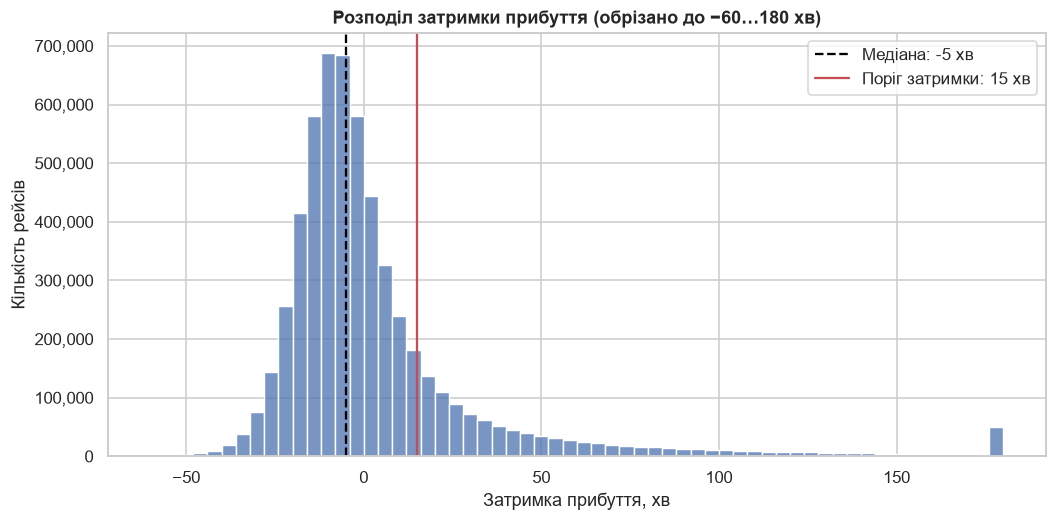

In [40]:
fig, ax = plt.subplots()
sns.histplot(done["ARRIVAL_DELAY"].clip(-60, 180), bins=60, ax=ax, color="#4C72B0")
ax.axvline(done["ARRIVAL_DELAY"].median(), color="black", ls="--",
           label=f"Медіана: {done['ARRIVAL_DELAY'].median():.0f} хв")
ax.axvline(DELAY_THRESHOLD, color="#C44E52", ls="-", label="Поріг затримки: 15 хв")
ax.set(title="Розподіл затримки прибуття (обрізано до −60…180 хв)",
       xlabel="Затримка прибуття, хв", ylabel="Кількість рейсів")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend()
save_fig(fig, "01_delay_distribution")
plt.show()

**Інтерпретація.** Розподіл одномодальний і помітно **правоасиметричний**. Пік припадає на інтервал від −10 до 0 хв, тобто найтиповіша ситуація – прибуття трохи раніше розкладу; медіана (−5 хв) лежить лівіше від порогу затримки. Зліва розподіл різко обривається приблизно на −60 хв: прибути значно раніше за розклад літак фізично не може.

Праворуч від порогу 15 хв починається довгий «хвіст», який тягнеться далеко за межі графіка (на рисунку його обрізано на 180 хв, стовпчик на правому краю акумулює всі більші значення). Саме цей хвіст і створює розрив між середнім і медіаною: 8,8 % виконаних рейсів перевищують верхню межу IQR у 40 хв, 47 172 рейси запізнилися більш ніж на 3 години, а 1348 – більш ніж на 10 годин.

### Рисунок 2. Частка затриманих рейсів за авіакомпаніями

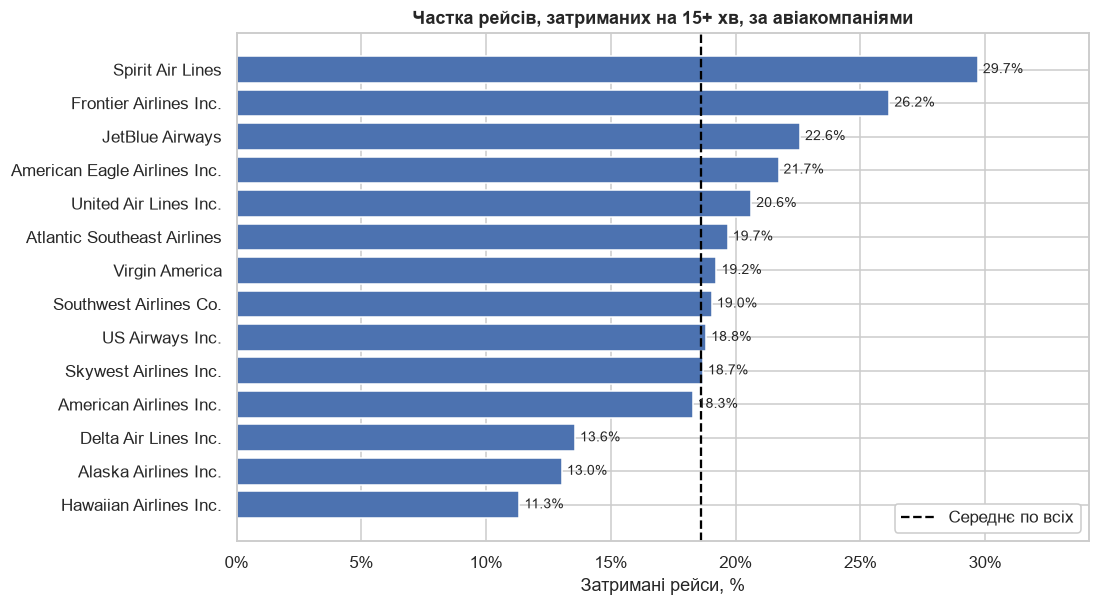

In [41]:
plot_data = airline_stats.sort_values("delayed_pct")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data.index, plot_data["delayed_pct"], color="#4C72B0")
ax.axvline(done["IS_DELAYED"].mean() * 100, color="black", ls="--", label="Середнє по всіх")
for y, v in enumerate(plot_data["delayed_pct"]):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set(title="Частка рейсів, затриманих на 15+ хв, за авіакомпаніями",
       xlabel="Затримані рейси, %", ylabel="")
ax.set_xlim(0, plot_data["delayed_pct"].max() * 1.15)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="lower right", framealpha=1)
save_fig(fig, "02_airlines_delayed_pct")
plt.show()

**Інтерпретація.** Найгірший результат у **Spirit Air Lines – 29,7 %** затриманих рейсів, найкращий у **Hawaiian Airlines – 11,3 %**; різниця становить **18,4 відсоткового пункта**. Пунктирна лінія середнього по всіх рейсах (18,6 %) ділить перевізників майже навпіл: вище за неї – шість компаній (Spirit, Frontier, JetBlue, American Eagle, United, Atlantic Southeast), нижче – вісім.

Важливо, що розмір перевізника не визначає якість. Найбільша за кількістю рейсів Southwest (1,24 млн рейсів) показує 19,0 % – майже рівно середній рівень, тоді як невеликі Spirit (115 тис.) і Frontier (90 тис.) очолюють антирейтинг, а невелика Hawaiian (76 тис.) його замикає. Три найкращі компанії – Hawaiian, Alaska і Delta – відриваються від решти: у них частка затриманих нижча за 14 %, тоді як у наступної за ними American Airlines уже 18,3 %.

### Рисунок 3. Розкид затримок за авіакомпаніями

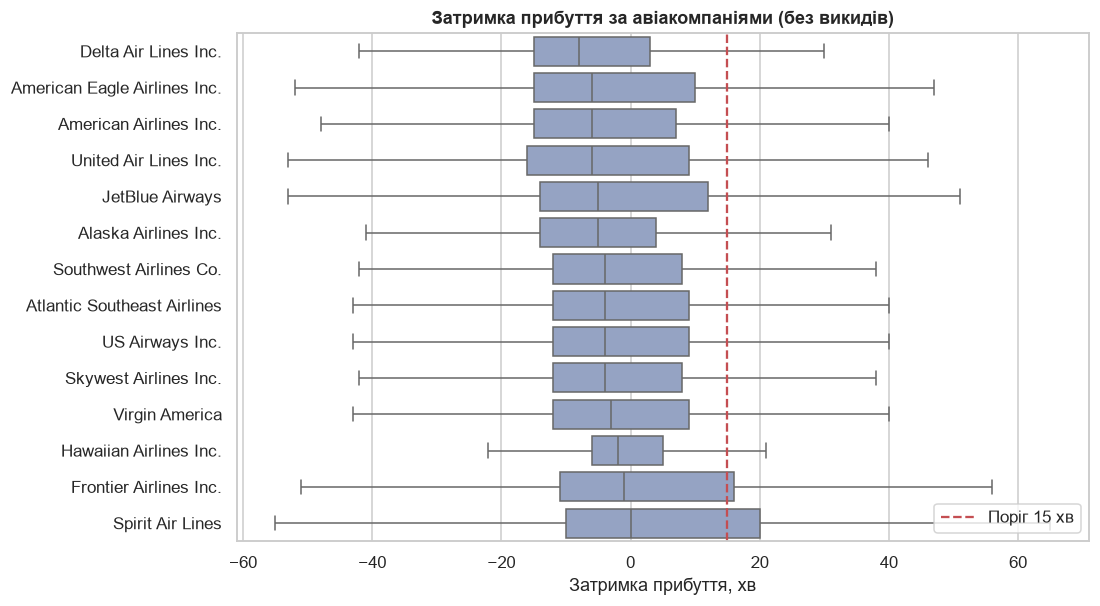

In [42]:
order = airline_stats.sort_values("median_delay").index
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=done, y="AIRLINE_NAME", x="ARRIVAL_DELAY", order=order,
            showfliers=False, color="#8DA0CB", ax=ax)
ax.axvline(DELAY_THRESHOLD, color="#C44E52", ls="--", label="Поріг 15 хв")
ax.set(title="Затримка прибуття за авіакомпаніями (без викидів)",
       xlabel="Затримка прибуття, хв", ylabel="")
ax.legend(loc="lower right")
save_fig(fig, "03_airlines_boxplot")
plt.show()

**Інтерпретація.** Медіани **в усіх 14 авіакомпаній нижчі за поріг 15 хв** і в 13 із них від’ємні: половина рейсів прибуває раніше розкладу. Виняток – Spirit із медіаною рівно 0 хв. Це ще раз показує, що проблема затримок – не в «типовому» рейсі, а у вузькій, але болючій групі сильно запізнених рейсів.

Ширина «коробки» (міжквартильний розмах) показує передбачуваність. Найширші коробки у **Spirit** і **Frontier** – їхній верхній квартиль сягає 16–20 хв, тобто понад чверть рейсів цих компаній уже формально затримані. Найвужча коробка у **Hawaiian Airlines**: від −6 до +5 хв, тобто половина її рейсів укладається в розкид усього 11 хвилин. Delta поєднує вузьку коробку з найнижчою медіаною (−8 хв) – найкращий баланс пунктуальності й передбачуваності серед великих перевізників. «Вуса» в усіх компаній витягнуті вправо, що знову відображає асиметрію розподілу.

### Рисунок 4. Динаміка затримок і скасувань за місяцями

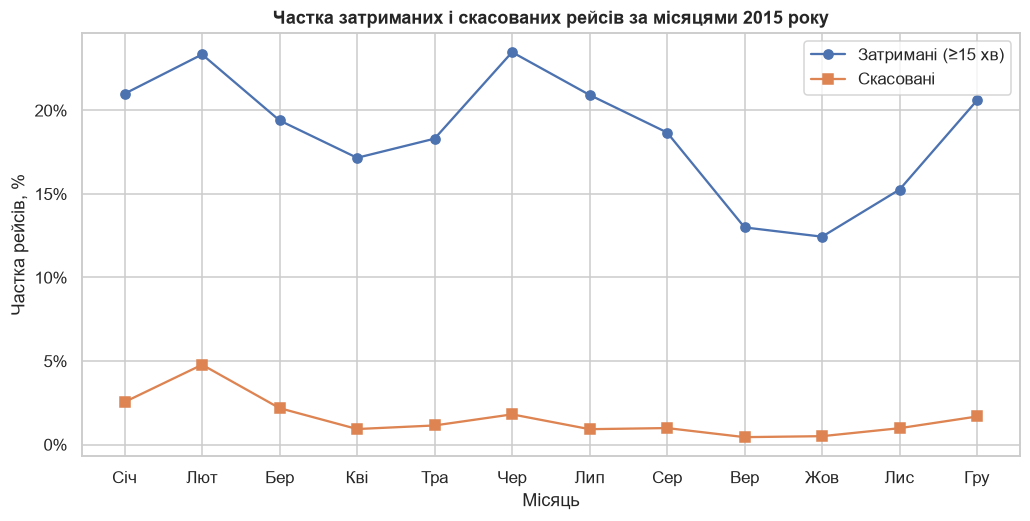

In [43]:
MONTH_NAMES = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер", "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["delayed_pct"], marker="o", label="Затримані (≥15 хв)")
ax.plot(monthly.index, monthly["cancelled_pct"], marker="s", label="Скасовані")
ax.set_xticks(range(1, 13), MONTH_NAMES)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set(title="Частка затриманих і скасованих рейсів за місяцями 2015 року",
       xlabel="Місяць", ylabel="Частка рейсів, %")
ax.legend()
save_fig(fig, "04_monthly_dynamics")
plt.show()

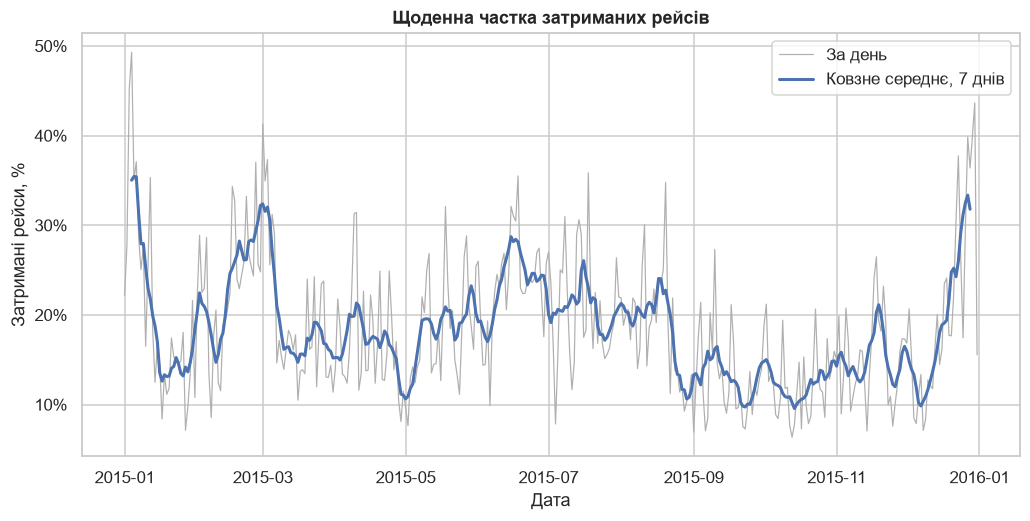

In [44]:
fig, ax = plt.subplots()
ax.plot(daily.index, daily, color="#B0B0B0", lw=0.8, label="За день")
ax.plot(daily_rolling.index, daily_rolling, color="#4C72B0", lw=2, label="Ковзне середнє, 7 днів")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set(title="Щоденна частка затриманих рейсів", xlabel="Дата", ylabel="Затримані рейси, %")
ax.legend()
save_fig(fig, "04b_daily_dynamics")
plt.show()

**Інтерпретація.** Крива затримок має **два піки**. Перший – зимовий: лютий (**23,3 %**) і січень (21,0 %), причина – снігові бурі й ожеледь. Другий, несподівано навіть вищий, – літній: **червень (23,5 %)** і липень (20,9 %), коли авіасистема перевантажена відпускними перевезеннями, а грозова активність зриває розклад. Найспокійніші місяці – **вересень (13,0 %) і жовтень (12,4 %)**: пасажиропотік спадає, погода ще стабільна. Розрив між найгіршим і найкращим місяцем становить 11 відсоткових пунктів, тобто сезон майже подвоює ризик затримки.

Скасування поводяться інакше: вони мають **один різкий пік у лютому (4,8 %)** – учетверо вище за річний рівень 1,5 %, і стабільно низькі значення з квітня по жовтень (0,45–1,15 %). Отже, екстремальна зимова погода не стільки затримує рейси, скільки повністю їх скасовує.

Графік щоденної динаміки показує, наскільки сильними є окремі погодні події. П’ять найгірших днів року – **4 січня (49,3 %)**, 3 січня (45,2 %), 30 грудня (43,7 %), 1 березня (41,3 %) і 29 грудня (39,9 %): у ці дні затримувався майже кожен другий рейс. Усі вони припадають на зимові шторми та післясвяткові пікові перевезення. Ковзне середнє за 7 днів згладжує щоденні коливання й підтверджує загальний W-подібний профіль року.

### Рисунок 5. Частка затриманих рейсів: день тижня × година вильоту

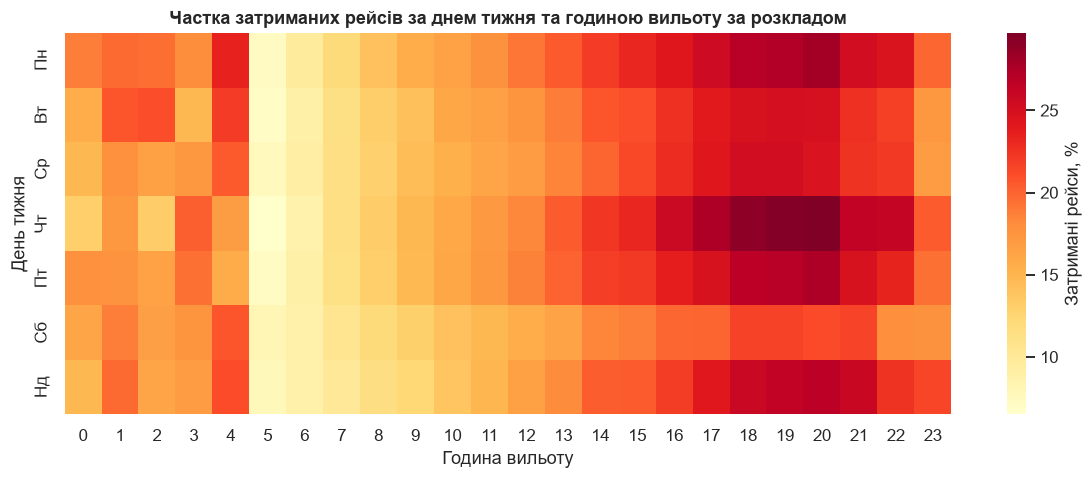

In [45]:
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(pivot_day_hour, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Затримані рейси, %"})
ax.set(title="Частка затриманих рейсів за днем тижня та годиною вильоту за розкладом",
       xlabel="Година вильоту", ylabel="День тижня")
save_fig(fig, "05_heatmap_day_hour")
plt.show()

**Інтерпретація.** Теплова карта показує чіткий **світлий вертикальний «коридор» о 5–7 годині ранку**: це найнадійніший час вильоту в будь-який день тижня (6,5–9,7 % затриманих). Далі кольори поступово темнішають зліва направо, і найтемніша зона припадає на **18–20 годину** (до 29,7 % у четвер). Це пряме візуальне підтвердження ланцюгового ефекту: затримки накопичуються протягом дня.

Між буднями й вихідними різниця помітна. **Субота – найсвітліший рядок**: вечірній максимум у ній лише 21,7 % проти 27–30 % у четвер і понеділок. Неділя та понеділок темніші за суботу, бо на них припадають повернення з вихідних і початок ділового тижня. Окремо виділяється невеликий темний «острівець» о 1–4 годині ночі (13–23 %): нічних рейсів мало, і це переважно сильно запізнені вечірні рейси, що «переїхали» за північ, тому відсоток рахується від малої бази.

### Рисунок 6. Структура причин затримок за авіакомпаніями

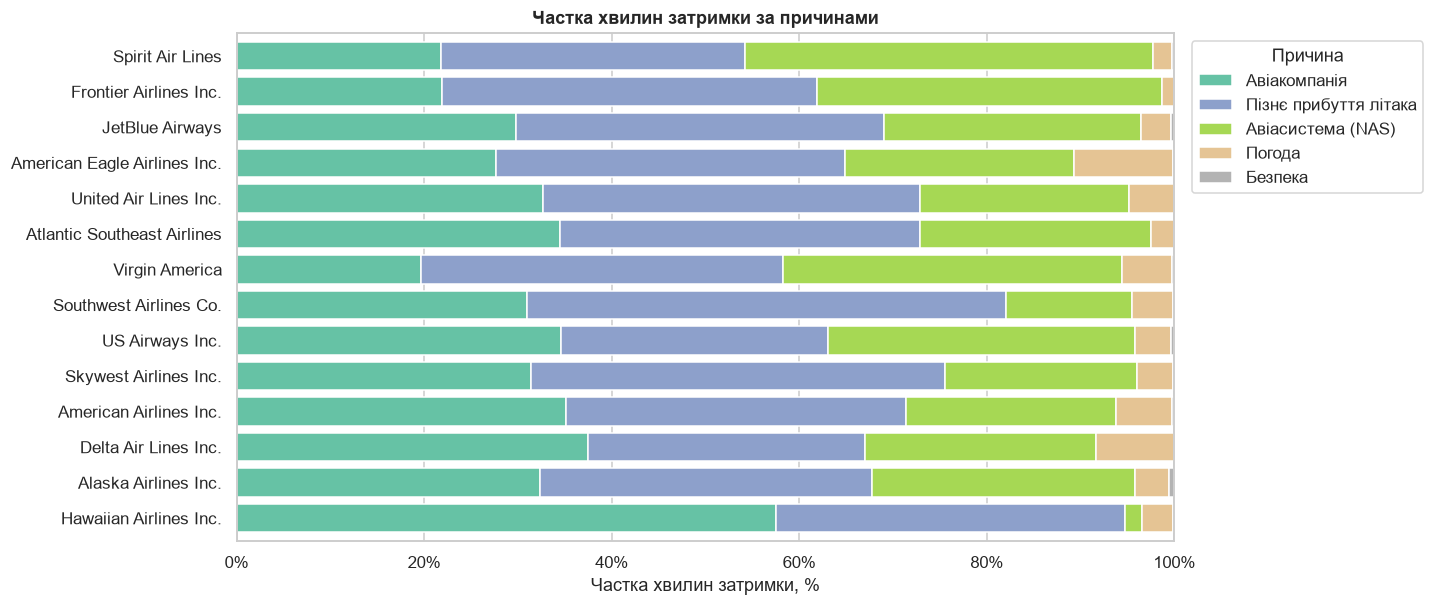

In [46]:
fig, ax = plt.subplots(figsize=(11, 6))
causes_by_airline_pct.iloc[::-1].plot.barh(stacked=True, ax=ax, width=0.8, colormap="Set2")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set(title="Частка хвилин затримки за причинами", xlabel="Частка хвилин затримки, %", ylabel="")
ax.set_xlim(0, 100)
ax.legend(title="Причина", bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "06_causes_by_airline")
plt.show()

**Інтерпретація.** Загалом у 2015 році на затримки припало **62,65 млн хвилин** – понад 119 років сумарного запізнення. Найбільший внесок дає **пізнє прибуття літака – 39,8 %** (24,96 млн хв), далі **вина авіакомпанії – 32,2 %** (20,17 млн хв) і **авіасистема NAS – 22,9 %** (14,34 млн хв). На погоду припадає лише **5,0 %**, на безпеку – **0,13 %**.

Ключовий висновок: дві перші причини, що разом дають **72 %** усіх хвилин, перебувають у зоні відповідальності самих перевізників, адже «пізнє прибуття літака» – це наслідок попередніх затримок того самого борту, тобто результат надто щільного розкладу й малих резервів часу.

Структура причин помітно різниться між компаніями. У **Hawaiian Airlines** 57,6 % хвилин – це власна вина авіакомпанії, а NAS дає лише 1,8 %: її рейси майже не залежать від перевантаженого континентального повітряного простору. Протилежний випадок – **Spirit**, де на NAS припадає 43,5 %, найбільше серед усіх: компанія літає переважно у завантажені хаби. У **Southwest** домінує пізнє прибуття літака (**51,0 %**) – наслідок моделі швидкого обороту літаків із мінімальними паузами між рейсами. Найбільша частка погоди в **American Eagle (10,6 %)**, що пояснюється мережею регіональних аеропортів із менш стійкою до погоди інфраструктурою.

### Рисунок 7. Взаємозв’язки числових ознак і дальність польоту

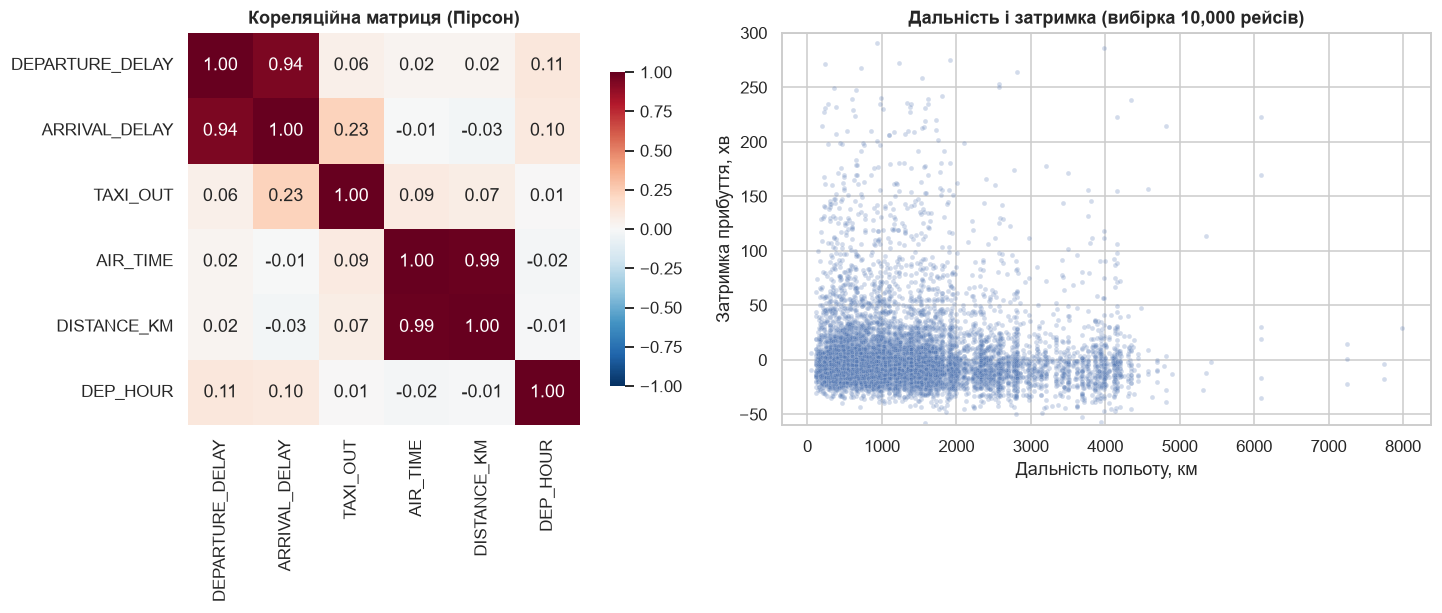

In [47]:
sample = done.sample(n=min(10_000, len(done)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.1]})

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, ax=axes[0], cbar_kws={"shrink": 0.8})
axes[0].set_title("Кореляційна матриця (Пірсон)")

sns.scatterplot(data=sample, x="DISTANCE_KM", y="ARRIVAL_DELAY", alpha=0.25, s=10, ax=axes[1])
axes[1].set_ylim(-60, 300)
axes[1].set(title=f"Дальність і затримка (вибірка {len(sample):,} рейсів)",
            xlabel="Дальність польоту, км", ylabel="Затримка прибуття, хв")
fig.tight_layout()
save_fig(fig, "07_correlations")
plt.show()

**Інтерпретація.** Найсильніший зв’язок – між затримкою вильоту й затримкою прибуття: **r = 0,94**. Це очікувано: літак майже не надолужує втрачений час у повітрі, тож запізнення на вильоті фактично переноситься на прибуття. Помірний зв’язок має час руління перед злетом (`TAXI_OUT`, **r = 0,23**) – завантаженість аеропорту додає хвилини до затримки. Година вильоту дає слабкий, але додатний зв’язок (**r = 0,10**), що узгоджується з «вечірнім» характером затримок.

Зв’язку затримки з **дальністю польоту практично немає**: Пірсон **−0,03**, Спірмен **−0,06**. Обидва коефіцієнти близькі до нуля, а від’ємний знак означає, що довгі рейси радше трохи пунктуальніші. Групування за квартилями дальності це підтверджує: частка затриманих у всіх чотирьох групах лежить у вузькому діапазоні **17,8–19,4 %**, хоча середня затримка найдовших рейсів (2,87 хв) помітно нижча за найкоротші (5,24 хв) – у довгому польоті є більше можливостей надолужити час. Діаграма розсіювання показує суцільну «хмару» без нахилу, що візуально підтверджує відсутність залежності.

Висока кореляція `AIR_TIME` і `DISTANCE_KM` (**r = 0,99**) очікувана й не є знахідкою: це по суті одна й та сама величина, виражена по-різному. Відповідь на П4: **величина затримки від дальності польоту практично не залежить**. Нагадаємо, що кореляція не доводить причинно-наслідкового зв’язку.

### Рисунок 8. Скасування за місяцями та причинами

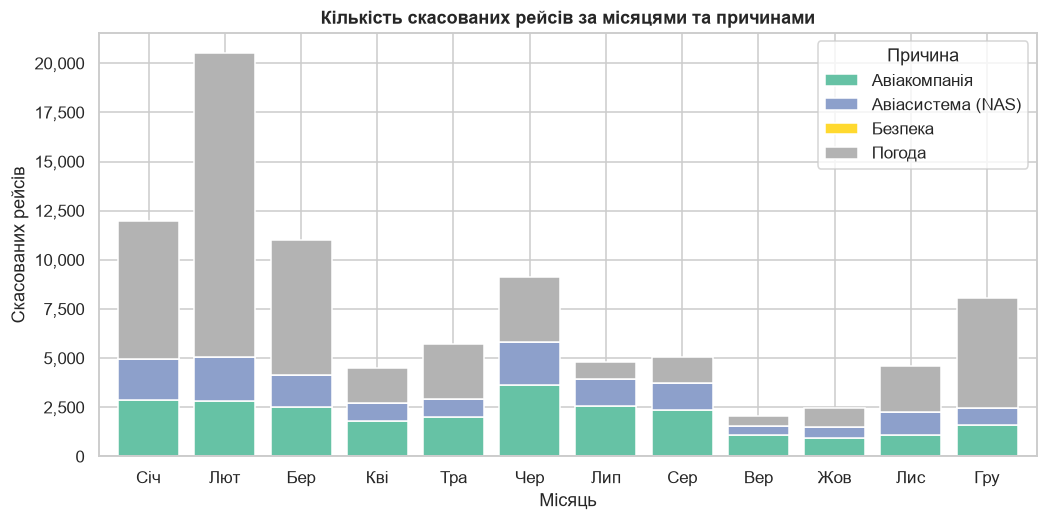

In [48]:
fig, ax = plt.subplots()
cancel_plot = cancel_crosstab.drop(index="Усього", columns="Усього")
cancel_plot.plot.bar(stacked=True, ax=ax, colormap="Set2", width=0.8)
ax.set_xticklabels([MONTH_NAMES[m - 1] for m in cancel_plot.index], rotation=0)
ax.set(title="Кількість скасованих рейсів за місяцями та причинами",
       xlabel="Місяць", ylabel="Скасованих рейсів")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(title="Причина")
save_fig(fig, "08_cancellations")
plt.show()

**Інтерпретація.** Усього у 2015 році скасовано **89 884 рейси (1,54 %)**. Пік однозначний – **лютий із 20 517 скасуваннями**, що майже вдвічі більше за наступний місяць. І цей пік **повністю пояснюється погодою**: з 20 517 лютневих скасувань **15 447 (75,3 %)** спричинені погодою. Зимові місяці загалом домінують: січень (11 982), березень (11 002) і грудень (8063) разом із лютим дають 57 % річних скасувань.

У цілому за рік **погода є причиною 54,3 %** скасувань (48 851 рейс), авіакомпанія – 28,1 % (25 262), авіасистема NAS – 17,5 % (15 749), безпека – лише 22 рейси за весь рік (0,02 %). Улітку структура змінюється: у червні (9120 скасувань) погода дає лише 36 %, а провідною причиною стає сама авіакомпанія (3619 рейсів) – це вже операційні, а не погодні зриви. Найспокійніші місяці – вересень (2075) і жовтень (2454).

## 8. Експорт даних для Tableau Public

Tableau Public погано працює з 5,8 млн рядків, тому готуємо агреговану таблицю: один рядок – місяць × авіакомпанія × аеропорт вильоту. У ній лише **суми й кількості**, а відсотки та середні Tableau рахує сам (`SUM(delayed) / SUM(completed)`), тому фільтри працюють коректно. Рейси з числовими кодами аеропортів у файл не потрапляють (немає координат).

Готову таблицю зберігаємо в `data/processed/`, а підсумкові таблиці аналізу – в `results/exports/`.

In [49]:
tableau_df = (
    flights.dropna(subset=["ORIGIN_NAME", "ORIGIN_LAT"])
    .groupby(["MONTH", "AIRLINE", "AIRLINE_NAME", "ORIGIN_AIRPORT", "ORIGIN_NAME",
              "ORIGIN_CITY", "ORIGIN_STATE", "ORIGIN_LAT", "ORIGIN_LON"], observed=True)
    .agg(
        flights=("CANCELLED", "size"),
        cancelled=("CANCELLED", "sum"),
        diverted=("DIVERTED", "sum"),
        completed=("IS_COMPLETED", "sum"),
        delayed=("IS_DELAYED", "sum"),
        arr_delay_sum=("ARRIVAL_DELAY", "sum"),
        late_minutes_sum=("ARRIVAL_LATE_MIN", "sum"),
        **{f"{c.lower()}_sum": (c, "sum") for c in CAUSE_COLS},
    )
    .reset_index()
)
tableau_df["MONTH_NAME"] = tableau_df["MONTH"].map(dict(enumerate(MONTH_NAMES, 1)))

tableau_path = PROCESSED_DIR / "flights_tableau.csv"
tableau_df.to_csv(tableau_path, index=False, encoding="utf-8")
print(f"Збережено {len(tableau_df):,} рядків у {tableau_path.relative_to(PROJECT_DIR)}")
print(f"Покрито рейсів: {tableau_df['flights'].sum():,} з {len(flights):,}")
tableau_df.head()

Збережено 12,382 рядків у data\processed\flights_tableau.csv
Покрито рейсів: 5,328,309 з 5,819,079


,MONTH,AIRLINE,AIRLINE_NAME,ORIGIN_AIRPORT,ORIGIN_NAME,ORIGIN_CITY,ORIGIN_STATE,ORIGIN_LAT,ORIGIN_LON,flights,cancelled,diverted,completed,delayed,arr_delay_sum,late_minutes_sum,airline_delay_sum,late_aircraft_delay_sum,air_system_delay_sum,weather_delay_sum,security_delay_sum,MONTH_NAME
0,1,AA,American Airlines Inc.,ABQ,Albuquerque International Sunport,Albuquerque,NM,35.04,-106.61,124,1,0,123,23,"1,145.00","1,654.00",841.00,107.00,425.00,0.00,0.00,Січ
1,1,AA,American Airlines Inc.,ATL,Hartsfield-Jackson Atlanta International Airport,Atlanta,GA,33.64,-84.43,397,1,0,396,78,"1,902.00","4,754.00",738.00,"2,898.00",651.00,43.00,0.00,Січ
2,1,AA,American Airlines Inc.,AUS,Austin-Bergstrom International Airport,Austin,TX,30.19,-97.67,654,20,0,634,102,"1,603.00","6,937.00","2,597.00","2,883.00",826.00,0.00,0.00,Січ
3,1,AA,American Airlines Inc.,BDL,Bradley International Airport,Windsor Locks,CT,41.94,-72.68,94,7,0,87,25,"1,230.00","1,811.00",338.00,894.00,425.00,66.00,0.00,Січ
4,1,AA,American Airlines Inc.,BHM,Birmingham-Shuttlesworth International Airport,Birmingham,AL,33.56,-86.75,58,0,0,58,10,"1,969.00","2,534.00","2,224.00",165.00,81.00,0.00,0.00,Січ


In [50]:
exports = {
    "kpi.csv": kpi.to_frame(),
    "airline_stats.csv": airline_stats,
    "airport_stats.csv": airport_stats,
    "pivot_day_hour.csv": pivot_day_hour,
    "pivot_season_time_of_day.csv": pivot_season_tod,
    "causes_by_airline_pct.csv": causes_by_airline_pct,
    "cancellations_month_reason.csv": cancel_crosstab,
    "monthly.csv": monthly,
    "correlations.csv": corr_pearson,
}
for file_name, table in exports.items():
    table.to_csv(EXPORT_DIR / file_name, encoding="utf-8")
print("Збережено:", ", ".join(exports))

Збережено: kpi.csv, airline_stats.csv, airport_stats.csv, pivot_day_hour.csv, pivot_season_time_of_day.csv, causes_by_airline_pct.csv, cancellations_month_reason.csv, monthly.csv, correlations.csv


## 9. Висновки

Проаналізовано **5 819 079 внутрішніх рейсів США за 2015 рік**. Затриманими (прибуття на 15+ хв пізніше розкладу) виявилися **18,6 %** виконаних рейсів, скасованими – **1,54 %**. Середня затримка прибуття становить 4,41 хв, медіана – −5 хв, а середнє запізнення саме затриманого рейсу – **58,9 хв**.

1. **П1 – авіакомпанії та аеропорти.** Розрив між перевізниками сягає **18,4 в. п.**: від **29,7 %** затриманих рейсів у Spirit Air Lines до **11,3 %** у Hawaiian Airlines. Рейтинги за затримками та скасуваннями не збігаються: American Eagle за затримками лише четверта (21,7 %), але скасовує **5,1 %** рейсів – учетверо більше за середнє. Серед 71 великого аеропорту найгірші – **Chicago O'Hare (24,1 %)**, LaGuardia (24,0 %) і Miami (23,1 %); найкращі – **Honolulu (10,8 %)**, Anchorage (12,6 %) і Kahului (13,2 %). Характерно, що в LGA і JFK медіанний час руління перед злетом сягає 23–24 хв проти 9–10 хв у Houston і Dallas, тобто затримки великих хабів значною мірою створює наземна завантаженість.

2. **П2 – динаміка в часі.** Рік має **два піки затримок**: зимовий (лютий – 23,3 %) і літній (червень – **23,5 %**), а найспокійніші місяці – вересень (13,0 %) і жовтень (12,4 %). Протягом доби частка затриманих зростає **втричі**: з 6,5–8 % о 5–6 годині ранку до **29,7 %** о 20-й годині (четвер). Це ланцюговий ефект: запізнення одного борту переноситься на всі його наступні рейси. Найнадійніший день тижня – **субота** (вечірній максимум лише 21,7 %). П’ять найгірших днів року – 4 січня (**49,3 %**), 3 січня, 30 грудня, 1 березня і 29 грудня – зимові шторми та післясвяткові пікові перевезення.

3. **П3 – причини.** Сумарно затримки склали **62,65 млн хвилин**. Найбільший внесок дає **пізнє прибуття літака – 39,8 %**, далі вина авіакомпанії – 32,2 %, авіасистема NAS – 22,9 %, погода – лише 5,0 %, безпека – 0,13 %. Отже, **близько 72 % хвилин затримки перебуває в зоні відповідальності перевізників**, а не погоди. Структура різниться між компаніями: у Southwest домінує пізнє прибуття літака (51,0 %) – наслідок щільного обороту бортів, у Spirit – NAS (43,5 %), у Hawaiian – власна вина (57,6 %) за майже нульового впливу NAS (1,8 %).

4. **П4 – дальність.** Зв’язку між дальністю польоту й затримкою **практично немає**: кореляція Пірсона **−0,03**, Спірмена **−0,06**. Частка затриманих у всіх чотирьох квартильних групах дальності лежить у вузькому діапазоні 17,8–19,4 %. Водночас середня затримка найдовших рейсів (2,87 хв) нижча, ніж найкоротших (5,24 хв): у тривалому польоті є більше можливостей надолужити час. Натомість найсильніший зв’язок у наборі – між затримкою вильоту й прибуття (**r = 0,94**): літак майже не компенсує втрачений час.

5. **П5 – скасування.** Скасовано **89 884 рейси**. Головна причина – **погода (54,3 %)**, далі авіакомпанія (28,1 %) і NAS (17,5 %); на безпеку припало лише 22 рейси за рік. Пік – **лютий (20 517 скасувань, 4,8 % усіх рейсів місяця)**, із яких 75,3 % спричинені погодою. За аеропортами найвища частка скасувань у **LaGuardia (4,55 %)**, Newark (3,06 %) і Chicago O'Hare (2,99 %) – тобто в перевантажених хабах Північного Сходу.

**Практичні рекомендації.**

*Пасажирам.* Обирати **ранкові рейси (виліт о 5–8 годині)**: ризик затримки там утричі нижчий, ніж увечері. За можливості уникати стикувань увечері та в хабах ORD, LGA, EWR. Для подорожей у лютому закладати резерв часу або розглядати альтернативні дати: у цьому місяці скасовується майже кожен двадцятий рейс. Для критично важливих поїздок звертати увагу не лише на середню затримку, а й на її розкид: у Frontier і Spirit він удвічі вищий (std 51,6 і 45,9 хв), ніж у Hawaiian (25,7 хв).

*Перевізникам.* Оскільки 72 % хвилин затримки дають пізнє прибуття літака та власні операційні причини, найбільший ефект дасть **збільшення резервів часу між рейсами одного борту**, особливо в другій половині дня, і посилення ранкової пунктуальності – саме ранкові запізнення запускають ланцюгову реакцію. Southwest із її часткою «пізнього прибуття» 51 % є найочевиднішим кандидатом на перегляд щільності обороту. Аеропортам-хабам варто працювати над скороченням часу руління: різниця в 14 хвилин між LGA і HOU у масштабі сотень тисяч рейсів дає мільйони хвилин затримки.

**Обмеження дослідження:**
- дані лише за 2015 рік і лише внутрішні рейси великих американських перевізників, тому висновки не можна механічно переносити на інші роки чи ринки;
- 486 165 рейсів жовтня (8,4 % набору) мають числові коди аеропортів замість IATA і не увійшли в аналіз на рівні аеропортів; на аналіз авіакомпаній, причин і динаміки це не вплинуло;
- причини затримок указують самі авіакомпанії за методикою BTS, тому розподіл між категоріями «вина авіакомпанії» та «авіасистема» може бути зміщеним;
- поля причин заповнені лише для рейсів із затримкою ≥ 15 хв, тому структура причин описує саме затримані рейси;
- кореляції показують статистичний зв’язок, але не доводять причинно-наслідкових зв’язків;
- викиди (502 588 рейсів із затримкою понад 40 хв) свідомо не видалялися, бо вони є реальною частиною досліджуваного процесу; щоб вони не спотворювали висновки, поряд із середнім послідовно використовувалася медіана.